# BÀI TẬP LỚN NHẬP MÔN HỌC MÁY (2026–2027)
## ĐỀ TÀI 14: DỰ ĐOÁN KHÁCH HÀNG HỦY ĐẶT PHÒNG KHÁCH SẠN
### NOTEBOOK 01: PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EXPLORATORY DATA ANALYSIS - EDA)

---
### Mục tiêu của Notebook:
1. Nạp và kiểm tra cấu trúc bộ dữ liệu thô **Hotel Booking Demand** (119,390 dòng x 32 cột).
2. Kiểm tra tỷ lệ dữ liệu bị thiếu (Missing Values) và đánh giá tính chất thiếu.
3. Kiểm tra các dòng trùng lặp và phân tích bản chất nghiệp vụ.
4. Phân tích phân phối của biến mục tiêu `is_canceled` (Đánh giá mức độ mất cân bằng dữ liệu).
5. Phân tích các đặc trưng số: phân phối, độ lệch, các giá trị cực trị và ngoại lệ (Outliers).
6. Phân tích các đặc trưng phân loại và mối quan hệ hai chiều (Bivariate Analysis) với tỷ lệ hủy phòng.
7. Phân tích ma trận tương quan Pearson để phát hiện mối quan hệ tuyến tính.
8. Tổng kết các phát hiện làm tiền đề cho giai đoạn Tiền xử lý (Preprocessing) và Kỹ thuật đặc trưng (Feature Engineering).


In [1]:
import sys
from pathlib import Path

# Thêm thư mục gốc của dự án vào sys.path để import các module trong src/
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import RAW_DATA_PATH, TARGET_COLUMN, LEAKAGE_COLUMNS, FIGURES_DIR, TABLES_DIR
from src.data_loader import load_raw_data
from src.utils import setup_visualization_style

# Thiết lập phong cách hiển thị đồ họa
setup_visualization_style()
pd.set_option("display.max_columns", None)
print("Môi trường và các thư viện đã được nạp thành công!")


Môi trường và các thư viện đã được nạp thành công!


## 1. Nạp dữ liệu và Tổng quan cấu trúc

In [2]:
# Nạp dữ liệu từ data/raw/hotel_bookings.csv
df = load_raw_data(RAW_DATA_PATH)
print(f"Số lượng quan sát (dòng) : {df.shape[0]:,}")
print(f"Số lượng thuộc tính (cột): {df.shape[1]}")
df.head(5)


2026-11-17 02:09:06,054 - INFO - Đang đọc dữ liệu từ: D:\NH-M-8-Machine-Learning\data\raw\hotel_bookings.csv


2026-11-17 02:09:06,383 - INFO - Đọc dữ liệu thành công! Kích thước: 119,390 dòng x 32 cột. Bộ nhớ ước tính: 29.15 MB


Số lượng quan sát (dòng) : 119,390
Số lượng thuộc tính (cột): 32


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
# Thông tin kiểu dữ liệu và số lượng giá trị non-null
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

## 2. Thống kê mô tả (Descriptive Statistics)

In [4]:
# Thống kê mô tả các biến số (Numerical Features)
df.describe().T


,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


In [5]:
# Thống kê mô tả các biến phân loại (Categorical Features)
df.describe(include=["object"]).T


,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613


## 3. Phân tích dữ liệu thiếu (Missing Values Analysis)

Các cột có giá trị thiếu:


,Số lượng thiếu,Tỷ lệ (%)
company,112593,94.307
agent,16340,13.686
country,488,0.409
children,4,0.003


C:\Users\Laptop\AppData\Local\Temp\ipykernel_7052\1096891863.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_df['Tỷ lệ (%)'], y=missing_df.index, palette='Reds_r', ax=ax)


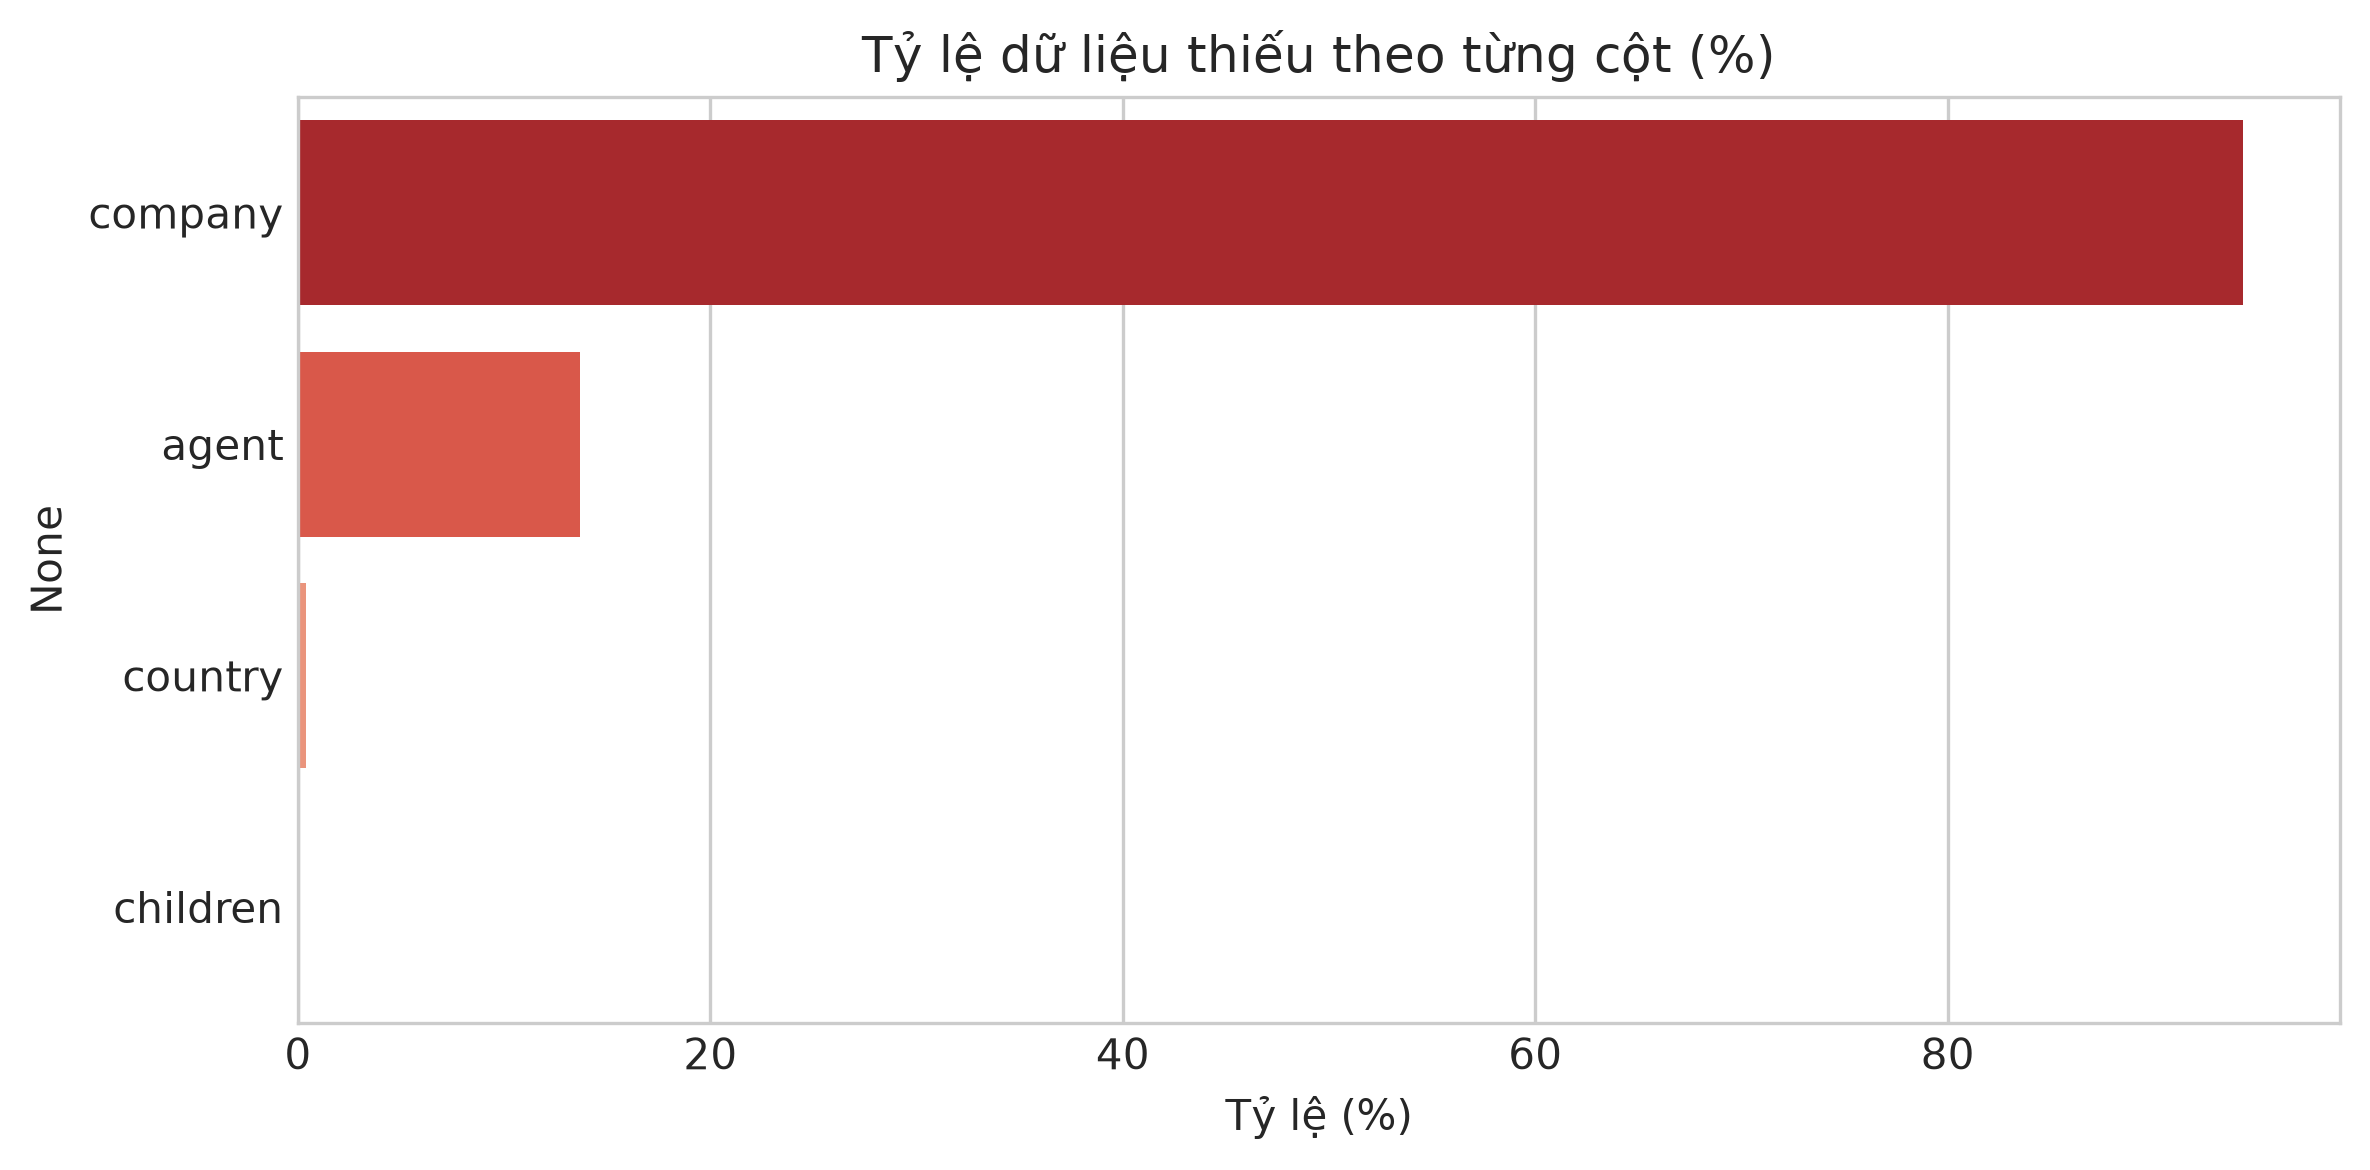

In [6]:
missing = df.isnull().sum()
missing_df = pd.DataFrame({
    'Số lượng thiếu': missing[missing > 0],
    'Tỷ lệ (%)': (missing[missing > 0] / len(df) * 100).round(3)
}).sort_values(by='Số lượng thiếu', ascending=False)

print("Các cột có giá trị thiếu:")
display(missing_df)

# Trực quan hóa tỷ lệ thiếu
if not missing_df.empty:
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.barplot(x=missing_df['Tỷ lệ (%)'], y=missing_df.index, palette='Reds_r', ax=ax)
    ax.set_title("Tỷ lệ dữ liệu thiếu theo từng cột (%)", fontsize=12)
    ax.set_xlabel("Tỷ lệ (%)")
    plt.tight_layout()
    plt.show()


### Nhận xét về dữ liệu thiếu:
- `company`: Thiếu tới **94.31%**. Cột này đại diện cho công ty đặt phòng, phần lớn khách hàng là cá nhân nên không có mã công ty. Không nên xóa dòng vì sẽ mất 94% dữ liệu. Cột này sẽ được loại bỏ hoặc gắn cờ phân loại có công ty hay không.
- `agent`: Thiếu **13.69%**. Đây là các đơn khách tự đặt trực tiếp không qua đại lý du lịch.
- `country`: Thiếu **0.41%** (488 mẫu). Có thể điền giá trị 'Unknown' hoặc mode.
- `children`: Thiếu **4 mẫu** (0.003%). Có thể điền median = 0.


## 4. Phân tích dữ liệu trùng lặp (Duplicate Records)

In [7]:
n_duplicates = df.duplicated().sum()
print(f"Tổng số dòng trùng lặp: {n_duplicates:,} dòng ({n_duplicates / len(df):.2%})")


Tổng số dòng trùng lặp: 31,994 dòng (26.80%)


### Nhận xét về trùng lặp:
- Bộ dữ liệu có 31,994 dòng có tất cả các thuộc tính trùng nhau hoàn toàn (26.8%).
- Tuy nhiên, trong dữ liệu đặt phòng khách sạn, không có khóa định danh cá nhân (ID đơn hàng, CMND/CCCD, tên khách hàng vì lý do bảo mật quyền riêng tư). Nhiều khách hàng khác nhau có thể đặt cùng một loại phòng, cùng số ngày, cùng ngày nhận phòng và cùng phân khúc.
- Trong Baseline và Pipeline A, nhóm sẽ giữ nguyên dữ liệu thực tế để phản ánh đúng phân phối gốc của thị trường, tránh mất mát thông tin tần suất của các nhóm khách hàng phổ biến.


## 5. Phân tích biến mục tiêu `is_canceled`

Phân phối biến mục tiêu:
  - Không hủy (0): 75,166 mẫu (62.96%)
  - Hủy phòng (1): 44,224 mẫu (37.04%)


C:\Users\Laptop\AppData\Local\Temp\ipykernel_7052\2050317214.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Không hủy (0)", "Hủy phòng (1)"], y=[counts[0], counts[1]], palette=["#2b5c8f", "#d9534f"], ax=axes[0])


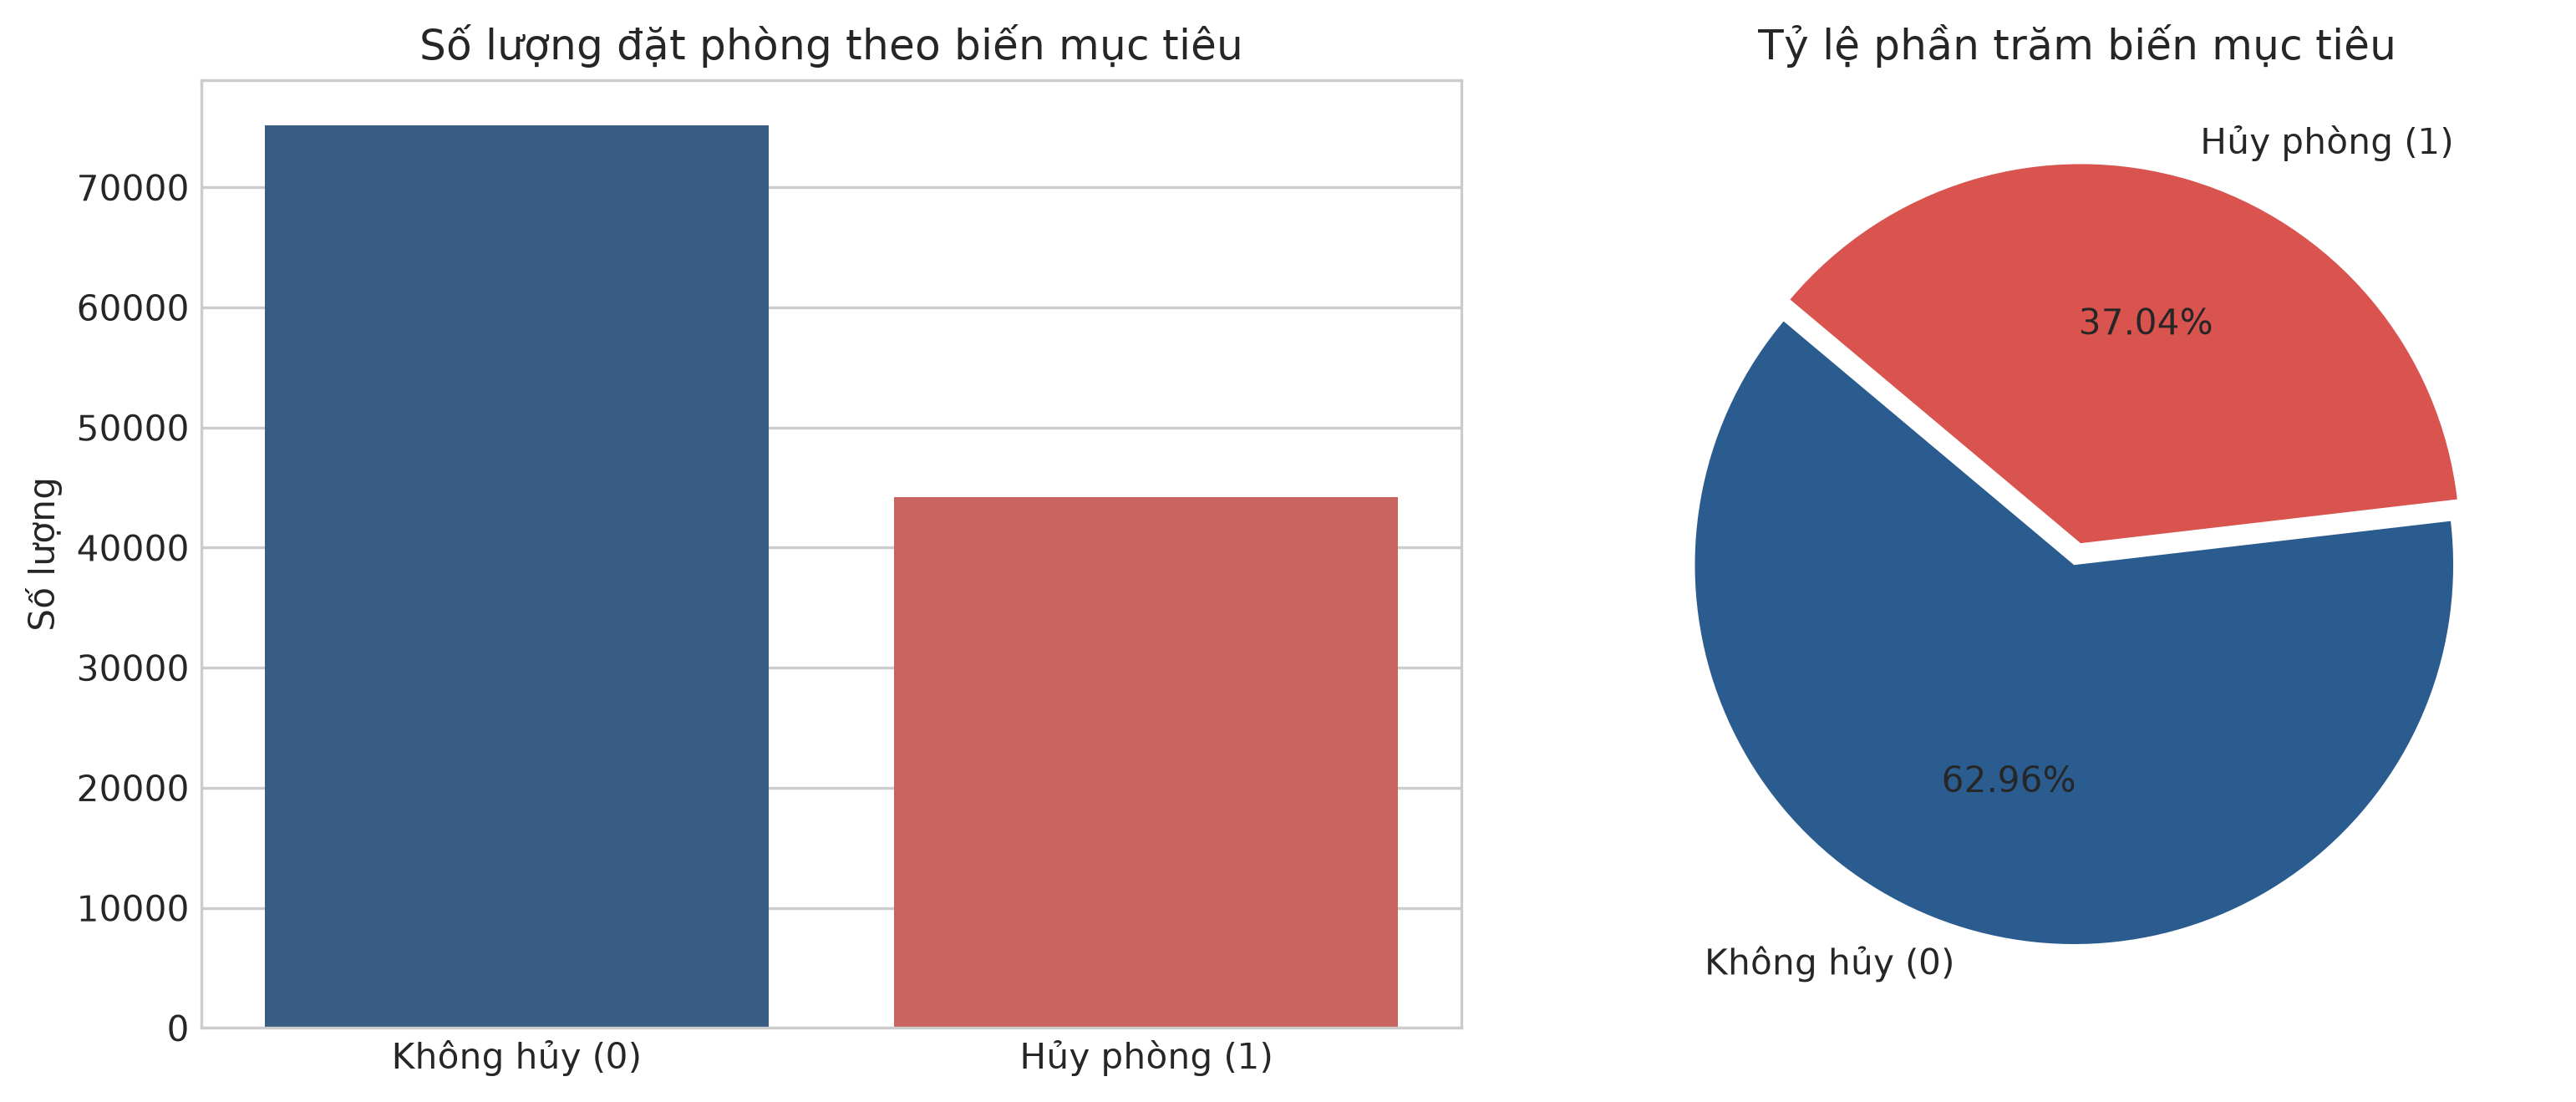

In [8]:
counts = df[TARGET_COLUMN].value_counts()
props = df[TARGET_COLUMN].value_counts(normalize=True)

print("Phân phối biến mục tiêu:")
for k in [0, 1]:
    name = "Không hủy (0)" if k == 0 else "Hủy phòng (1)"
    print(f"  - {name}: {counts[k]:,} mẫu ({props[k]:.2%})")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.barplot(x=["Không hủy (0)", "Hủy phòng (1)"], y=[counts[0], counts[1]], palette=["#2b5c8f", "#d9534f"], ax=axes[0])
axes[0].set_title("Số lượng đặt phòng theo biến mục tiêu")
axes[0].set_ylabel("Số lượng")

axes[1].pie([counts[0], counts[1]], labels=["Không hủy (0)", "Hủy phòng (1)"],
            autopct="%1.2f%%", colors=["#2b5c8f", "#d9534f"], startangle=140, explode=(0.03, 0.03))
axes[1].set_title("Tỷ lệ phần trăm biến mục tiêu")
plt.tight_layout()
plt.show()


### Nhận xét về biến mục tiêu:
- Tỷ lệ hủy phòng là **37.04%** (44,224 đơn), tỷ lệ không hủy là **62.96%** (75,166 đơn).
- Dữ liệu có mức độ mất cân bằng vừa phải (Moderate Imbalance, tỷ lệ xấp xỉ 1.7 : 1).
- Vì vậy:
  1. Khi chia dữ liệu Train/Test, **bắt buộc dùng `stratify=y`** để giữ nguyên phân phối lớp.
  2. Chỉ số **Accuracy sẽ không phản ánh toàn diện** hiệu năng mô hình (Baseline đoán toàn bộ là 0 đã đạt ~63% Accuracy).
  3. Cần tập trung vào **Precision, Recall và F1-Score** của Lớp 1 (Hủy phòng) để đánh giá khả năng phát hiện rủi ro.


## 6. Phân tích mối quan hệ giữa các đặc trưng và tỷ lệ hủy phòng

In [9]:
# 6.1. Loại khách sạn (hotel)
hotel_cxl = df.groupby('hotel')[TARGET_COLUMN].agg(Total='count', Canceled='sum')
hotel_cxl['Cancel_Rate_%'] = (hotel_cxl['Canceled'] / hotel_cxl['Total'] * 100).round(2)
display(hotel_cxl)

# 6.2. Hình thức đặt cọc (deposit_type)
deposit_cxl = df.groupby('deposit_type')[TARGET_COLUMN].agg(Total='count', Canceled='sum')
deposit_cxl['Cancel_Rate_%'] = (deposit_cxl['Canceled'] / deposit_cxl['Total'] * 100).round(2)
display(deposit_cxl)

# 6.3. Phân khúc thị trường (market_segment)
seg_cxl = df.groupby('market_segment')[TARGET_COLUMN].agg(Total='count', Canceled='sum')
seg_cxl['Cancel_Rate_%'] = (seg_cxl['Canceled'] / seg_cxl['Total'] * 100).round(2)
display(seg_cxl.sort_values(by='Total', ascending=False))


,Total,Canceled,Cancel_Rate_%
hotel,,,
City Hotel,79330,33102,41.73
Resort Hotel,40060,11122,27.76


,Total,Canceled,Cancel_Rate_%
deposit_type,,,
No Deposit,104641,29694,28.38
Non Refund,14587,14494,99.36
Refundable,162,36,22.22


,Total,Canceled,Cancel_Rate_%
market_segment,,,
Online TA,56477,20739,36.72
Offline TA/TO,24219,8311,34.32
Groups,19811,12097,61.06
Direct,12606,1934,15.34
Corporate,5295,992,18.73
Complementary,743,97,13.06
Aviation,237,52,21.94
Undefined,2,2,100.00


### Nhận xét đặc trưng quan trọng:
1. **Loại khách sạn (`hotel`):** City Hotel có tỷ lệ hủy (**41.73%**) cao hơn đáng kể so với Resort Hotel (**27.76%**). Khách đặt City Hotel thường linh hoạt hơn và dễ thay đổi lịch trình.
2. **Hình thức đặt cọc (`deposit_type`):**
   - Đáng chú ý: Nhóm đặt cọc không hoàn lại (`Non Refund`) có tỷ lệ hủy lên tới **99.36%**! Đây là hiện tượng nổi tiếng trong bộ dữ liệu này: các công ty du lịch/đoàn đặt giữ chỗ với điều khoản non-refundable, nhưng khi hủy đoàn thì đơn vẫn được ghi nhận là hủy mà không được hoàn tiền.
   - Nhóm `No Deposit` có tỷ lệ hủy là **28.38%**.
3. **Phân khúc thị trường (`market_segment`):** Nhóm `Groups` có tỷ lệ hủy cao nhất (**61.06%**), tiếp theo là `Online TA` (**36.72%**). Nhóm `Direct` (khách đặt trực tiếp) có tỷ lệ hủy thấp nhất (**15.37%**).


## 7. Phân tích ảnh hưởng của thời gian đặt trước (`lead_time`)

C:\Users\Laptop\AppData\Local\Temp\ipykernel_7052\3868874941.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=lead_cxl.index, y=lead_cxl['Cancel_Rate_%'], palette='Reds', ax=ax)


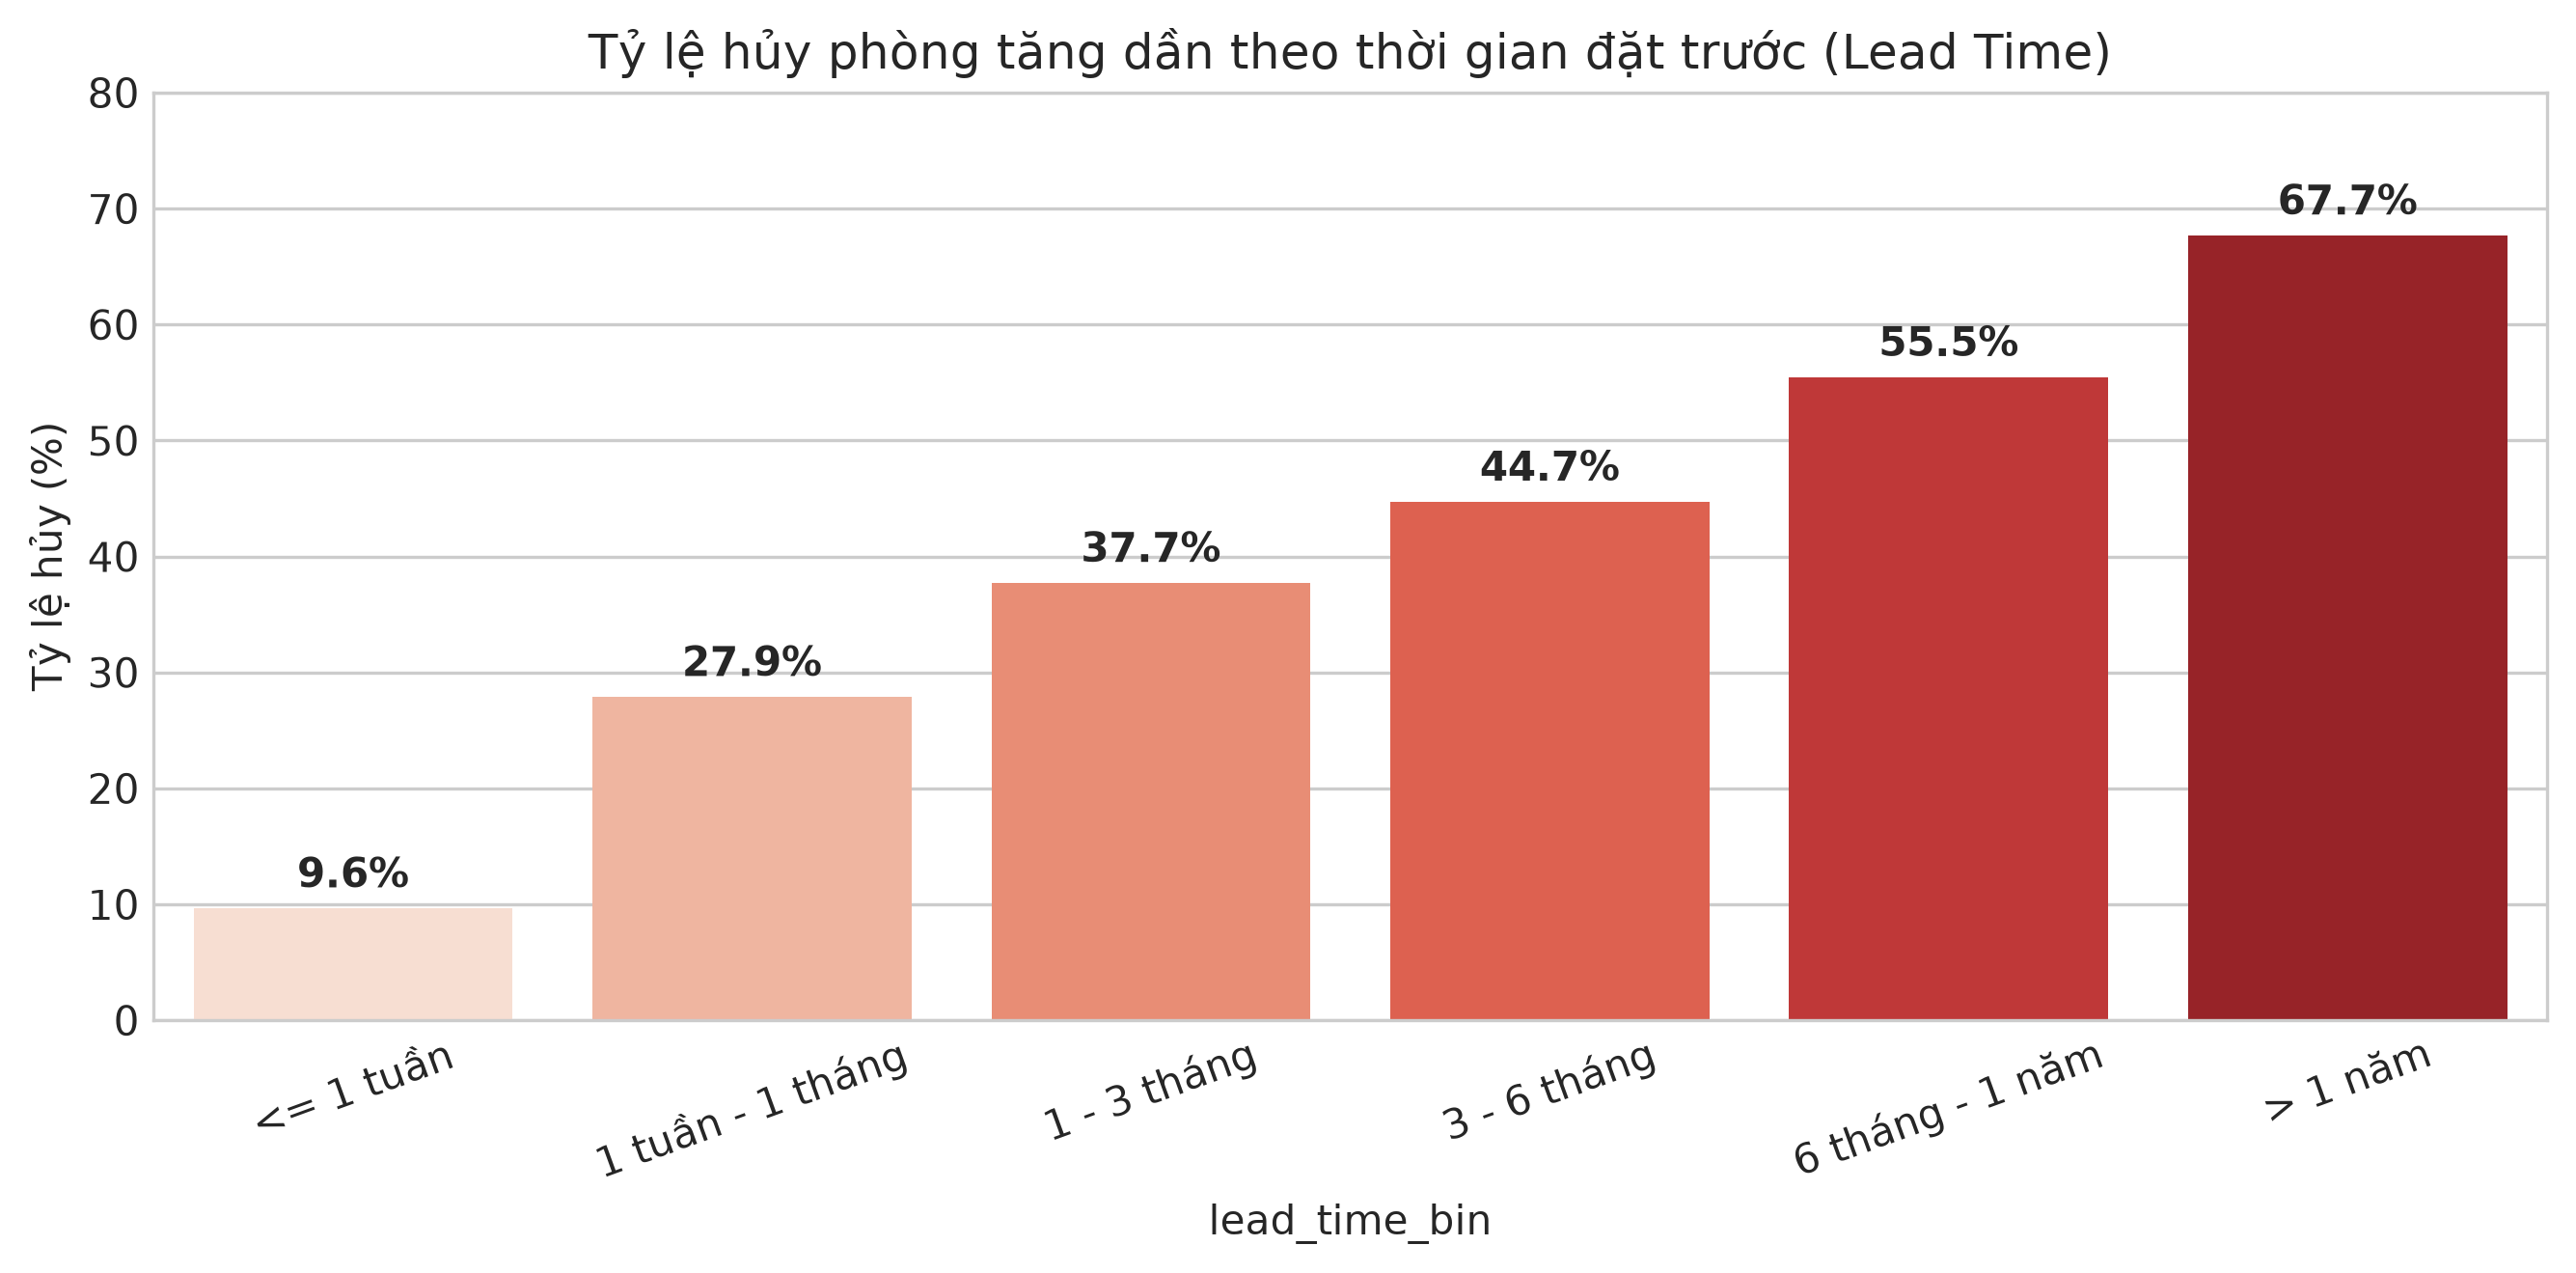

In [10]:
lead_bins = [-1, 7, 30, 90, 180, 365, 1000]
lead_labels = ["<= 1 tuần", "1 tuần - 1 tháng", "1 - 3 tháng", "3 - 6 tháng", "6 tháng - 1 năm", "> 1 năm"]
df['lead_time_bin'] = pd.cut(df['lead_time'], bins=lead_bins, labels=lead_labels)

lead_cxl = df.groupby('lead_time_bin', observed=False)[TARGET_COLUMN].agg(Total='count', Canceled='sum')
lead_cxl['Cancel_Rate_%'] = (lead_cxl['Canceled'] / lead_cxl['Total'] * 100).round(2)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(x=lead_cxl.index, y=lead_cxl['Cancel_Rate_%'], palette='Reds', ax=ax)
ax.set_title("Tỷ lệ hủy phòng tăng dần theo thời gian đặt trước (Lead Time)", fontsize=12)
ax.set_ylabel("Tỷ lệ hủy (%)")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width()/2., p.get_height() + 1), ha='center', va='bottom', fontweight='bold')
ax.set_ylim(0, 80)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 8. Ma trận tương quan (Correlation Matrix)

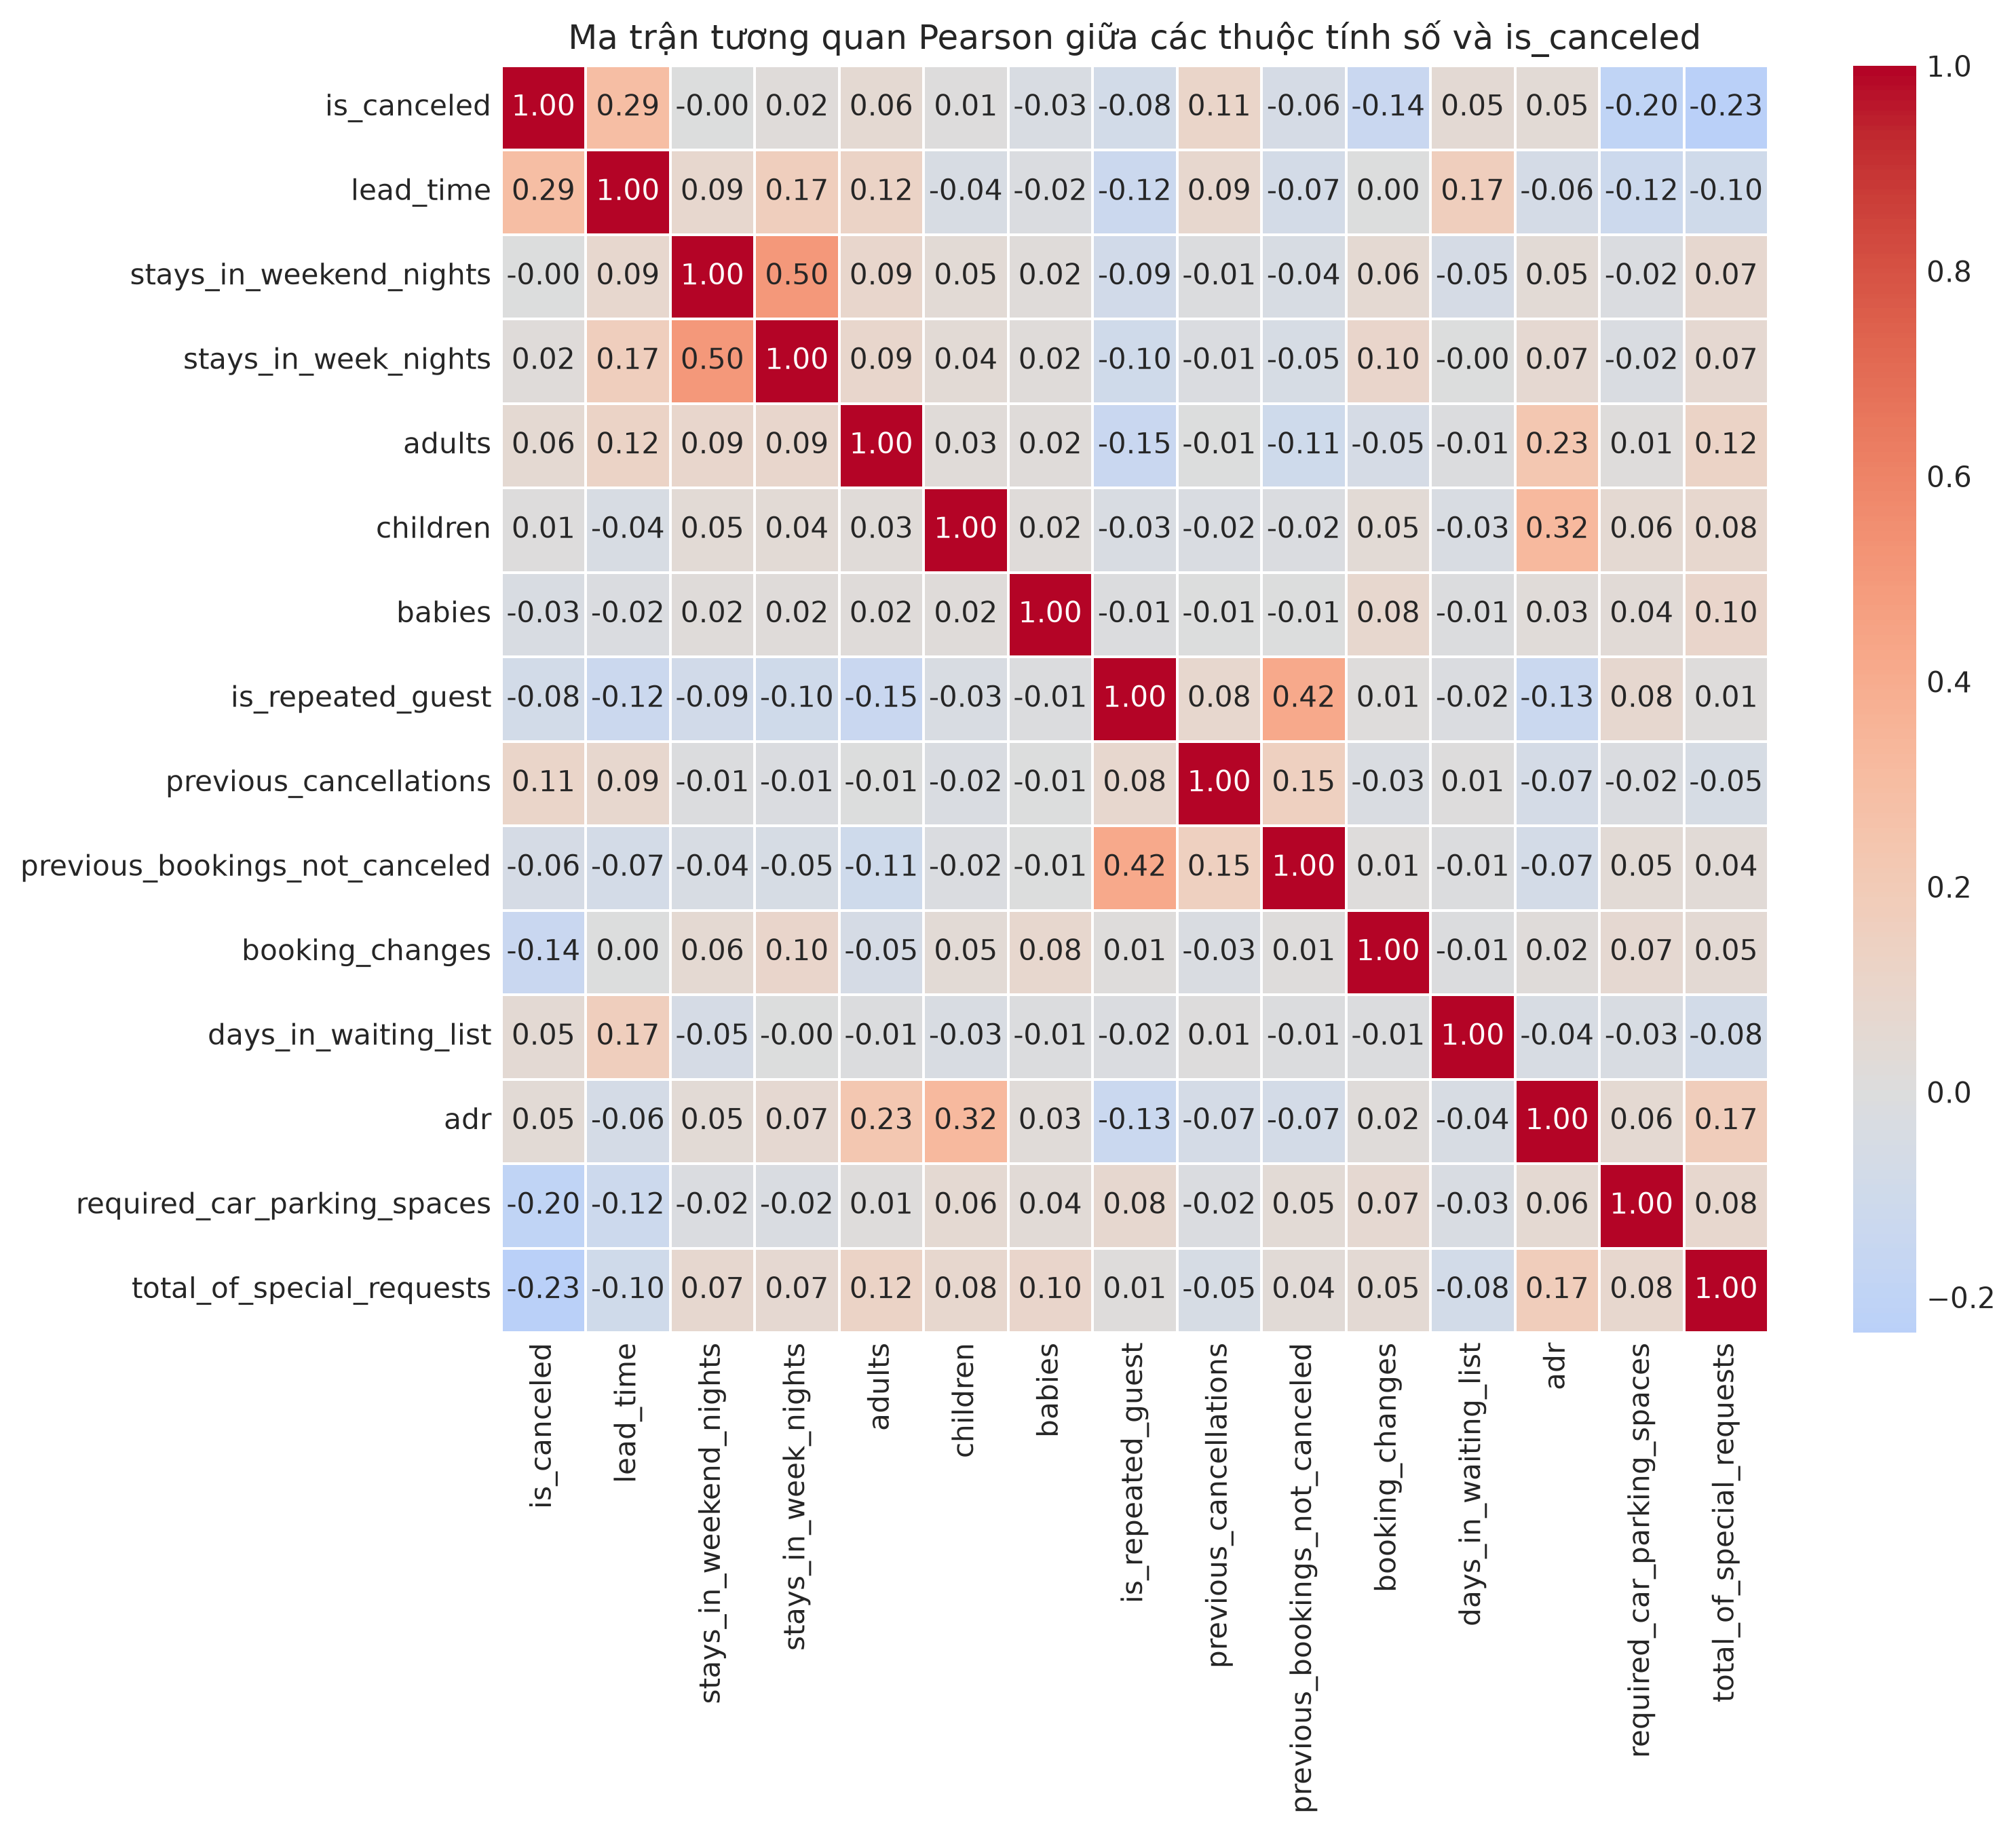

In [11]:
num_cols = [
    'is_canceled', 'lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights',
    'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations',
    'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list',
    'adr', 'required_car_parking_spaces', 'total_of_special_requests'
]

corr = df[num_cols].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, linewidths=0.5)
plt.title("Ma trận tương quan Pearson giữa các thuộc tính số và is_canceled", fontsize=12)
plt.tight_layout()
plt.show()


## 9. Tổng kết và Quyết định Tiền xử lý (Preprocessing Strategy)

Qua phân tích khám phá dữ liệu, nhóm rút ra các kết luận định hướng giải pháp:

1. **Phòng ngừa Data Leakage:**
   - Loại bỏ hoàn toàn `reservation_status` và `reservation_status_date`.
2. **Chiến lược phân chia tập dữ liệu:**
   - Sử dụng `train_test_split` tỷ lệ **80% Train - 20% Test** có `stratify=y` và `random_state=42`.
3. **Thiết kế Pipeline A (Cơ bản - Baseline Preprocessing):**
   - Loại bỏ cột leakage.
   - `SimpleImputer`: median cho biến số, most_frequent cho biến phân loại.
   - `OneHotEncoder(handle_unknown='ignore')` cho biến phân loại.
   - `StandardScaler` cho thuật toán KNN.
4. **Thiết kế Pipeline B (Cải tiến - Feature Engineering):**
   - Tạo các đặc trưng phái sinh:
     - `total_nights = stays_in_weekend_nights + stays_in_week_nights`
     - `total_guests = adults + children + babies`
     - `is_family = (children > 0) | (babies > 0)`
     - `room_type_changed = (reserved_room_type != assigned_room_type)`
     - `lead_time_group` (rời rạc hóa thời gian đặt trước)
   - Xử lý bất thường: lọc bỏ hoặc xử lý trường hợp tổng số khách bằng 0, giá phòng ADR âm.
   - Xử lý mất cân bằng lớp thông qua `class_weight='balanced'` trong Decision Tree.
